# <font color=blue>OPTIM/OPTECH Laboratory Learning Session IV: </font> 
## <font color=blue>Evolutionary Algorithms (EA)</font> 

### `MASTEAM`: Master's degree in Applied Telecommunications and Engineering Management
### `MATT`: Master's degree in Advanced Telecommunication Technologies
### `CoDaS`: Erasmus Mundus master's degree in Communications, Engineering and Data Science
### `AI4CI`: Master's degree in Artificial Intelligence for Connected Industries


###  <font color=#922B21>Castelldefels School of Telecommunications and Aerospace Engineering (EETAC)</font>

**<font color=teal>Cristina Cervelló-Pastor (cristina.cervello@upc.edu)</font>**

<div class="alert alert-block alert-info">

<font size="4"><font color=blue><b>PROBLEM:</b></font></font> 
<br /><br />

<b>Design a network using Evolutionary Algorithms</b>
<br /> <br /> 
In this session we will deal with Evolutionary Algorithms to design a network, i.e., decide what links do you have to use to transport a percentage of a set of demands with a maximum cost constraint. Therefore, it is a multiobjective problem with two opposite objective functions.
<br /> <br /> 
Design the edge capacities of a network of 5 nodes, with 7 potential edges. Each edge could have a capacity of 0 (if not created), 4, 16, or 64 units of 155 Mb/s (or STM-1, STM-4, STM-16, STM-64), to satisfy a given set of demands.
</div>


In [1]:
from pyomo.environ import *
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import random
import math 

import warnings
warnings.filterwarnings("ignore")

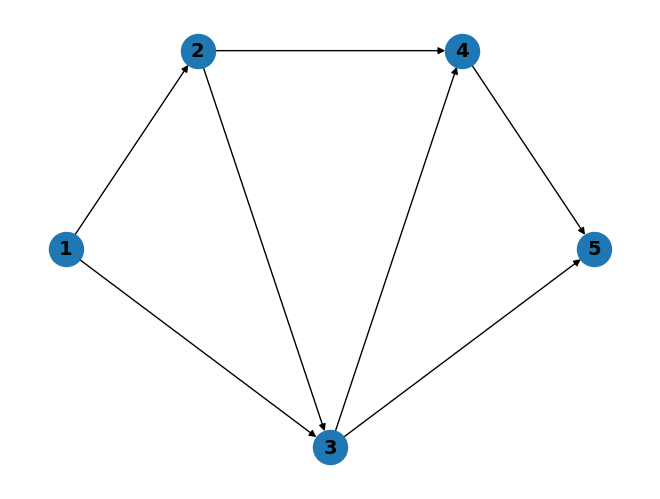

In [2]:
# Graph of the network

G = nx.DiGraph()
N = [1,2,3,4,5]
E = [(1,2),(1,3),(2,3),(2,4),(3,4),(3,5),(4,5)]

G.add_nodes_from(N)
G.add_edges_from(E, capacity=0, cost=0, color='black', weight=1)
    
CostMatrix = [[0 for i in range(len(N))] for j in range(len(N))]
CapacityMatrix = [[0 for i in range(len(N))] for j in range(len(N))]

#dictionary with the node position
fixed_positions = {1:(0,3),2:(2,6),3:(4,0),4:(6,6),5:(8,3)} 
fixed_nodes = fixed_positions.keys()
pos = nx.spring_layout(G, pos=fixed_positions, fixed=fixed_nodes)

    
nx.draw(G, pos, node_size=600, with_labels=True, font_size=14, font_weight='bold')
plt.show()
plt.close()

In [3]:
# Required demands
# (origin, destination, value)(units of 155 Mb/s: 0,1,4,16,64)
 
demands = [
            [1,4,1]   #demand 1 (origin, destination, value)
           ,[2,3,4]   #demand 2
           ,[1,5,16]  #demand 3
           ,[4,5,64]  #demand 4
          ]


In [29]:
# Number of individuals per generation
NumIndividuals = 20

# Number of generations
NumGenerations = 15

# Maximum cost of the solution
CostLimit = 15000

# Minimum availability of the solution
AvLimit = 0.5

# Crossover fraction, in Reproduction options, specifies the fraction of the population, 
# other than elite children, that are crossover children.
pc = 0.2 # Probability of crossover

# The remaining individuals, other than elite children, are mutation children. 
pm = 0.1 # Probability of mutation

# cost of one STM-N module (N = 0, 1, 4, 16, 64)
cost = [0, 500, 1000, 2000, 3000]

# Set of genes for an individual
geneSet = {0,1,2,3,4}

# Edge colors
colors = ['black','blue','green','cyan','red']

# Link Types
links = ['None','STM-1','STM-4','STM-16','STM-64']


In [30]:
""" Class of a Solution of the network design: set of links, cost and availabiliy """ 

class Solution:
    def __init__(self, individual, cost, availability):
        self.individual = individual
        self.cost = cost
        self.availability = availability
        

In [31]:
""" Fill network link capacity with the information of an individual (solution)
     0 means no link; 1 means edge of capacity of 155 Mb/s (STM-1); 
     2 means 622 Mb/s (4 STM-1 or 1 STM-4); 3 means 2.5 Gb/s (STM-16); 
     4 means 10 Gb/s (STM-64)"""
    
def FillCapacity(G, individual):

    for i in range(len(E)):
        if (individual[i] == 0): G.edges[E[i][0],E[i][1]]['capacity'] = 0
        elif (individual[i] == 1): G.edges[E[i][0],E[i][1]]['capacity'] = 1
        elif (individual[i] == 2): G.edges[E[i][0],E[i][1]]['capacity'] = 4
        elif (individual[i] == 3): G.edges[E[i][0],E[i][1]]['capacity'] = 16
        elif (individual[i] == 4): G.edges[E[i][0],E[i][1]]['capacity'] = 64
            
        G.edges[E[i][0],E[i][1]]['cost'] = 0 if individual[i] == 0 \
                                               else cost[individual[i]-1]
                
    for (i,j) in E:
        CapacityMatrix[i-1][j-1] = G.edges[i,j]['capacity']
        CostMatrix[i-1][j-1] = G.edges[i,j]['cost']

In [32]:
""" Total cost of network link capacity """

def Cost(capacity):
    c = 0.0

    for i in range(len(E)):       
        c = c + cost[capacity[i]]

    return(c)

In [33]:
""" Compute constrained shorts paths for each demand  """

def ComputeConstraintShortPaths(G, demands):
    
    import pyomo.environ
    import logging

    logging.getLogger('pyomo.core').setLevel(logging.ERROR)
    
    model = AbstractModel()
     
    model.Nodes = Set(initialize=N)
    model.Arcs = Set(dimen=2, initialize=E)
   
    # Demands
    model.D = Set(initialize=[i for i in range(len(demands))])
    # Source nodes
    model.source = Param(model.D, default=[demands[i][0]\
                                           for i in range(len(demands))])
    # Destination nodes
    model.destination = Param(model.D, default=[demands[i][1] \
                                                for i in range(len(demands))])
    # Traffic demand value
    model.demand = Param(model.D, default=[demands[i][2] \
                                           for i in range(len(demands))])
    
    # The flow over each edge due to each demand
    model.f = Var(model.Arcs, model.D, within=Binary, initialize=0)

    # Variable x indicates if each edge is used or not;  
    # xe=1 edge e is used; xe=0 edge e is not used
    model.x = Var(model.Arcs, within=Binary, initialize=0)
   
    # Objective Function
    def cost_rule(model):
        return sum((model.x[i,j]*CostMatrix[i-1][j-1]) for (i, j) in model.Arcs)

    model.cost= Objective(rule=cost_rule, sense=minimize)
    
    # Flow conservation constraint
    def flow_rule(model, k, d):
        inFlow  = sum(model.f[i,j,d] for (i,j) in model.Arcs if j == k)
        if (k == demands[d][0]):
            inFlow = inFlow + 1
        outFlow = sum(model.f[i,j,d] for (i,j) in model.Arcs if i == k)
        if (k == demands[d][1]):
            outFlow = outFlow + 1
        
        return inFlow == outFlow
    model.flow = Constraint(model.Nodes, model.D, rule=flow_rule)

    # Link capacity constraint
    def limit_rule(model, i, j):
        return sum(model.f[i,j,d]*model.demand[d] for d in model.D) <=\
                    model.x[i, j]*CapacityMatrix[i-1][j-1]
    model.limit = Constraint(model.Arcs, rule=limit_rule)
    
    # Solve the model

    instance  = model.create_instance()

    opt = SolverFactory('glpk')
    results = opt.solve(instance)
    
    # Get how many demands have obtained a path
    num=0
    for d in instance.D:
        find=0
        for i in N:
            for j in N:
                if (i,j) in E:
                    if instance.f[i,j,d].value == 1: 
                        num = num + 1
                        find = 1;
                if find == 1: break
            if find == 1: break
                
    return(num/len(demands))


In [34]:
""" Percentage of demands that find path """ 

def Percentage(G, demands):    
    p = 1
    d = demands[:]
    while (True):
        if ( ComputeConstraintShortPaths(G, d) != 0 ):
            return (p)
        else: # no demand of the current list has found a path
            if ( len(d) > 1 ):
                del d[len(d)-1] # remove one demand of the list
                p = len(d) / len(demands) 
            else:
                return (0) # no demand has found a path

In [35]:
""" Calculate Cost and Availability of an individual """

def MeasureIndividual(individual):
    
    solution = Solution(None, None, None)
    Gp = G.copy()
    FillCapacity(Gp, individual)

    solution.individual = individual
    solution.cost = Cost(individual)
    solution.availability = Percentage(Gp, demands)

    return(solution)


In [36]:
""" Create a solution """

def CreateSolution(individual,cost,availability):
    
    solution = Solution(None, None, None)

    solution.individual = individual
    solution.cost = cost
    solution.availability = availability

    return(solution)


In [37]:
""" Generates random population of individuals """

def InitialPopulation ():
    
    global CurrentIndividuals, generation
  
    CurrentIndividuals = []
    generation = 1
    solution = Solution(None, None, None)
   
    i=1  
    while i <= NumIndividuals:
        solution = MeasureIndividual([np.random.randint(0,5) for r in range(len(E))])
        if solution.availability  >= AvLimit and solution.cost <= CostLimit:
            CurrentIndividuals.append(solution)
            i = i+1


In [38]:
""" Obtain the list of dominant individuals """ 

def Dominance(list):
    
    ld =[]  # List of identifiers of dominant individuals
    DominantIndividuals = [] # List of dominant individuals
    
    
    
    for i in range(len(list)):
        # compare one individual with the rest of individuals
        dominant = True
        c = list[i].cost
        av = list[i].availability

        for j in range(len(list)):
            if (i==j): continue # not compared with itself

            if ((c > list[j].cost and av == list[j].availability) or \
                (c == list[j].cost and av < list[j].availability) or \
                (c > list[j].cost and av < list[j].availability)):
                dominant = False
                break
                

        if (dominant == True):
            if list[i] not in DominantIndividuals: DominantIndividuals.append(list[i])
            ld.append(i)

    return (ld, DominantIndividuals)


In [39]:
""" Selection of two parents """ 

def Parents(len):

    p1 = np.random.randint(0,len)
    while (True):
        p2 = np.random.randint(0,len)
        if p2 != p1: return(p1,p2)
        
    return(p1,p2)


In [40]:
""" Returns True or False based on a probability """ 

def Decision(probability):
    return random.random() < probability


In [41]:
""" Cross two parents with certain probability pc """ 

def CrossParents(p1, p2):
    
    if Decision(pc):
        child1 = Solution(None, None, None)
        child2 = Solution(None, None, None)

        # One-point crossover 
        position = np.random.randint(1,len(E))
        
        print("Parents", p1.individual, p2.individual)   
        print('Cross from gene:', position)

        child1.individual = p1.individual[:]
        child2.individual = p2.individual[:]   
        
        for i in range (position, len(E)):
            g = child1.individual[i]
            child1.individual[i] = child2.individual[i]
            child2.individual[i] = g
             
        
        return (True, child1, child2)
    else:
        return (False, [], [])


In [42]:
""" Crossover of all individuals with certain probability pc """ 

def Crossover(IndividualsToReproduce):
    
    lc =[]  # List of identifiers of cross individuals
    CrossoverChildren = [] # List of resulting crossover children
    
    for i in range(math.ceil(len(IndividualsToReproduce)/2)):
        p1, p2  = Parents(len(IndividualsToReproduce)) # Select two parents
        parent1 = IndividualsToReproduce[p1]
        parent2 = IndividualsToReproduce[p2]
        
        c, child1, child2 = CrossParents(parent1, parent2)
        
        if c: 
            child1 = MeasureIndividual(child1.individual)
            if child1.availability  >= AvLimit and child1.cost <= CostLimit:
                if p1 not in lc: lc.append(p1)
                if child1 not in CrossoverChildren: CrossoverChildren.append(child1)       
                print("\n   Child 1", child1.individual)   
            else: print("\n   Child 1 does not comply with the constraints\n")

            child2 = MeasureIndividual(child2.individual)
            if child2.availability  >= AvLimit and child2.cost <= CostLimit:
                if p2 not in lc: lc.append(p2)  
                if child2 not in CrossoverChildren: CrossoverChildren.append(child2)                 
                print("   Child 2", child2.individual,"\n") 
            else: print("\n   Child 2 does not comply with the constraints\n")
                
    
    return(lc, CrossoverChildren)
        

In [43]:
""" First Mutation of one individual decreasing one gene.  
    The smaller the gene, the smaller the capacity of the 
    associated edges (and so the infrastructure cost) """ 

def FirstMutation(parent):
    
    child = list(parent)
    solution = Solution(None, None, None)
    repeat = True
    # we want to decrease a gene higher than the minimum value (0 in this case)
    while (repeat): 
        index = random.randrange(0, len(parent))
        if child[index] != min(geneSet):
            repeat = False
    validGene = False
    while (not validGene):
        newGene = random.sample(geneSet, 1)
        if newGene[0] < child[index]:
            child[index] = newGene[0] 
            validGene = True

    solution = MeasureIndividual(child)
    if solution.availability  >= AvLimit  and solution.cost <= CostLimit:
        return (True,child)
    else: 
        return (False, [])


In [44]:
""" Second Mutation of one individual increasing one gene. 
    Tends to improve the availability of the network by
    increasing the capacity of edges """ 

def SecondMutation(parent):
    
    child = list(parent)
    solution = Solution(None, None, None)
    repeat = True
    # we want to increase a gene lower than the maximum value (4 in this case)
    while (repeat): 
        index = random.randrange(0, len(parent))
        if child[index] != max(geneSet):
            repeat = False
    validGene = False
    while (not validGene):
        newGene = random.sample(geneSet, 1)
        if newGene[0] > child[index]:
            child[index] = newGene[0] 
            validGene = True

    solution = MeasureIndividual(child)
    if solution.availability  >= AvLimit and solution.cost <= CostLimit:
        return (True,child)
    else: 
        return (False, [])

In [45]:
""" Mutation of remaining individuals with certain probability """ 

def Mutation(IndividualsToMutate):
    
    for i in range(len(IndividualsToMutate)):
        parent = IndividualsToMutate[i].individual
        if Decision(pm):
            validmutate1, ind = FirstMutation(IndividualsToMutate[i].individual)
            if validmutate1:
                IndividualsToMutate[i].individual = ind
            validmutate2, ind = SecondMutation(IndividualsToMutate[i].individual)
            if validmutate2:
                IndividualsToMutate[i].individual = ind
            if (not validmutate1) and (not validmutate2):
                print("individual", IndividualsToMutate[i].individual, "not mutated")
            else:
                print("individual", parent, "mutate to -----> ", ind)
        else:
            print("individual", IndividualsToMutate[i].individual, "not mutated")
        
            

In [46]:
""" Plot a population of individuals """ 

def PlotPopulation(IndividualList, title): 
    
    plt.figure()
    plt.axes()
    plt.xlim((0,30000))
    plt.ylim((0,1))
    x = [IndividualList[i].cost for i in range(len(IndividualList))]
    y = [IndividualList[i].availability for i in range(len(IndividualList))]
    plt.xlabel('Cost', fontsize=12,fontweight='bold')
    plt.ylabel('Availability', fontsize=12, fontweight='bold')    
    plt.scatter(x, y, color='red')
    plt.title(title, fontsize= 18, color='blue')
    plt.show()


In [47]:
""" Draw the network related to an individual """ 

def DrawFinalNetworks(IndividualList):

    for i in range(len(IndividualList)): 
        l = [IndividualList[i].individual[e] for e in range(len(E))]
        c = [colors[l[e]] for e in range(len(E))]
        link = [links[l[e]] for e in range(len(E))]
        edge_labels = dict(zip(E, link))
        nx.draw(G, pos, node_size=600, with_labels = True, font_size=14, \
                font_weight='bold', edge_color=c, width=l, label=colors)
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)
        plt.show()



In [48]:
""" Print individuals, their cost and availability for one generation """ 

def PrintGenerationInfo(generation, ListIndividuals):
    
    print("\nGENERATION:",generation,"\n")
    for i in range(len(ListIndividuals)):
        print ("Individual:",ListIndividuals[i].individual, \
               "Cost:",ListIndividuals[i].cost, \
               "Availability:",ListIndividuals[i].availability)

In [49]:
def main():
    
    global CurrentIndividuals, generation, NextIndividuals, GlobalDominantIndividuals
    GlobalDominantIndividuals=[]

    #### INITIAL POPULATION
    InitialPopulation()
    
    PrintGenerationInfo(generation, CurrentIndividuals)
        
    PlotPopulation(CurrentIndividuals, "Generation 1")

    ####  REPEAT UNTIL A SOLUTION IS FOUND OR 
    ####  A MAXIMUM NUMBER OF GENERATIONS IS ACHIEVED
    
    while (generation < NumGenerations):
            
        NextIndividuals=[]    
        del NextIndividuals[:]
    
        ##### SELECTION PROCESS

        #### Select non-dominated solutions of this generation. Elitism.      
        DominantIndividuals = []
        ListDominants = []
        
        ListDominants, DominantIndividuals = Dominance(CurrentIndividuals)
        
        IndividualsToReproduce = CurrentIndividuals[:]
        
        # Elite children (non-dominated individuals) go directly to the next generation
        for i in range(len(DominantIndividuals)):
            if CurrentIndividuals[ListDominants[i]] not in NextIndividuals: 
                NextIndividuals.append(CurrentIndividuals[ListDominants[i]])
            if CurrentIndividuals[ListDominants[i]] not in GlobalDominantIndividuals:              
                GlobalDominantIndividuals.append(CurrentIndividuals[ListDominants[i]])
         
            
            IndividualsToReproduce.remove(CurrentIndividuals[ListDominants[i]])
          
    
        ### REPRODUCTION PROCESS to generate the new generation

        ### CROSSOVER
                
        # The crossover probability specifies the fraction of individuals 
        # in the next generation, other than elite children, 
        # that are created by crossover.
    
        print("\n\n >>>> CROSSOVER PHASE (with probability", pc, ")\n\n")
        
        ListCrossover=[]
        CrossoverChildren=[]
        
        del ListCrossover[:]
        del CrossoverChildren [:]
        
        ListCrossover, CrossoverChildren = Crossover(IndividualsToReproduce)
        print("\nNumber of Crossover Children:",len(CrossoverChildren),"\n")
 
        IndividualsToMutate=[]
        del IndividualsToMutate[:]
        IndividualsToMutate = IndividualsToReproduce[:]
        
     
        for i in range(len(ListCrossover)):
            IndividualsToMutate.remove(IndividualsToReproduce[ListCrossover[i]])
            
        for i in range(len(CrossoverChildren)):
            if (len(NextIndividuals)<NumIndividuals):
                NextIndividuals.append(CrossoverChildren[i])
            
        
        ### MUTATION PROCESS      
        
        # The remaining individuals that are not crossover children and are 
        # not elite children, will be mutated with probability pm
    
        print("\n\n >>>> MUTATION PHASE (with probability", pm, ")\n\n")
        
        Mutation(IndividualsToMutate)
   
        for i in range(len(IndividualsToMutate)):
            if (len(NextIndividuals)<NumIndividuals):
                NextIndividuals.append(IndividualsToMutate[i])
        
        del CurrentIndividuals[:]

        for i in range(len(NextIndividuals)):
            CurrentIndividuals.append(NextIndividuals[i])
        
        generation = generation + 1
        
        PrintGenerationInfo(generation, CurrentIndividuals)
        
        PlotPopulation(CurrentIndividuals, "Generation %s" % generation)




GENERATION: 1 

Individual: [2, 1, 3, 3, 4, 0, 2] Cost: 9500.0 Availability: 0.5
Individual: [4, 0, 2, 4, 1, 0, 2] Cost: 8500.0 Availability: 0.5
Individual: [3, 1, 2, 1, 2, 0, 1] Cost: 5500.0 Availability: 0.5
Individual: [2, 2, 4, 3, 2, 2, 1] Cost: 9500.0 Availability: 0.5
Individual: [0, 1, 4, 3, 4, 2, 0] Cost: 9500.0 Availability: 0.5
Individual: [4, 3, 4, 3, 2, 3, 2] Cost: 14000.0 Availability: 0.75
Individual: [1, 0, 4, 3, 4, 4, 4] Cost: 14500.0 Availability: 0.5
Individual: [1, 0, 3, 1, 0, 3, 3] Cost: 7000.0 Availability: 0.5
Individual: [3, 1, 2, 1, 4, 1, 3] Cost: 9500.0 Availability: 0.5
Individual: [0, 3, 4, 1, 1, 2, 0] Cost: 7000.0 Availability: 0.5
Individual: [1, 3, 2, 3, 2, 4, 3] Cost: 11500.0 Availability: 0.75
Individual: [1, 0, 3, 0, 4, 3, 0] Cost: 7500.0 Availability: 0.5
Individual: [2, 2, 4, 0, 4, 4, 4] Cost: 14000.0 Availability: 0.5
Individual: [0, 3, 2, 3, 3, 4, 0] Cost: 10000.0 Availability: 0.5
Individual: [2, 2, 2, 2, 2, 2, 3] Cost: 8000.0 Availability: 0.5
I

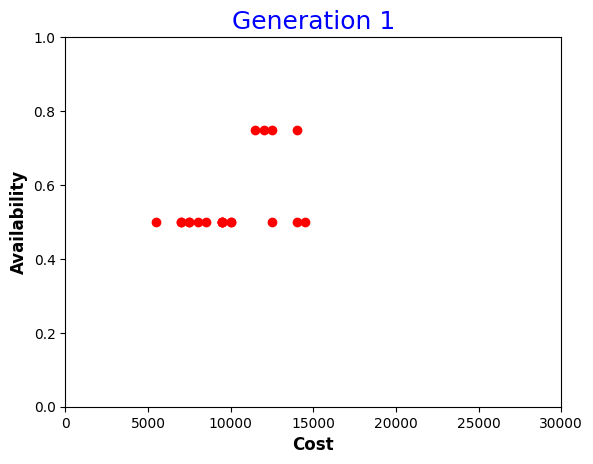



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [3, 4, 4, 4, 1, 2, 0] [4, 1, 2, 4, 0, 3, 1]
Cross from gene: 4

   Child 1 [3, 4, 4, 4, 0, 3, 1]
   Child 2 [4, 1, 2, 4, 1, 2, 0] 

Parents [1, 0, 4, 3, 4, 4, 4] [2, 2, 2, 2, 2, 2, 3]
Cross from gene: 4

   Child 1 [1, 0, 4, 3, 2, 2, 3]
   Child 2 [2, 2, 2, 2, 4, 4, 4] 


Number of Crossover Children: 4 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [2, 1, 3, 3, 4, 0, 2] not mutated
individual [4, 0, 2, 4, 1, 0, 2] mutate to ----->  [4, 0, 2, 4, 0, 0, 3]
individual [2, 2, 4, 3, 2, 2, 1] mutate to ----->  [4, 2, 4, 3, 2, 2, 1]
individual [0, 1, 4, 3, 4, 2, 0] not mutated
individual [4, 3, 4, 3, 2, 3, 2] not mutated
individual [1, 0, 3, 1, 0, 3, 3] not mutated
individual [3, 1, 2, 1, 4, 1, 3] not mutated
individual [0, 3, 4, 1, 1, 2, 0] not mutated
individual [1, 0, 3, 0, 4, 3, 0] not mutated
individual [2, 2, 4, 0, 4, 4, 4] not mutated
individual [0, 3, 2, 3, 3, 4, 0] not mutated
individual [4, 2, 4, 0, 4, 3, 1] no

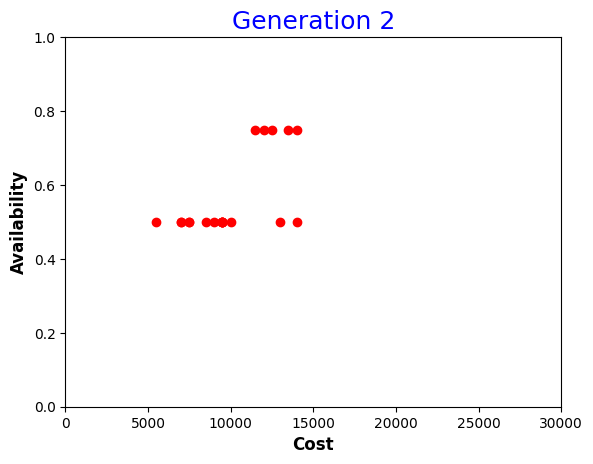



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [0, 3, 4, 1, 1, 2, 0] [4, 0, 2, 4, 0, 0, 3]
Cross from gene: 4

   Child 1 does not comply with the constraints

   Child 2 [4, 0, 2, 4, 1, 2, 0] 


Number of Crossover Children: 1 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [3, 4, 4, 4, 0, 3, 1] not mutated
individual [4, 1, 2, 4, 1, 2, 0] not mutated
individual [1, 0, 4, 3, 2, 2, 3] not mutated
individual [2, 2, 2, 2, 4, 4, 4] not mutated
individual [2, 1, 3, 3, 4, 0, 2] not mutated
individual [4, 2, 4, 3, 2, 2, 1] not mutated
individual [0, 1, 4, 3, 4, 2, 0] not mutated
individual [4, 3, 4, 3, 2, 3, 2] not mutated
individual [1, 0, 3, 1, 0, 3, 3] not mutated
individual [3, 1, 2, 1, 4, 1, 3] not mutated
individual [0, 3, 4, 1, 1, 2, 0] not mutated
individual [1, 0, 3, 0, 4, 3, 0] not mutated
individual [2, 2, 4, 0, 4, 4, 4] not mutated
individual [0, 3, 2, 3, 3, 4, 0] not mutated
individual [4, 2, 4, 0, 4, 3, 1] not mutated
individual [1, 2, 4, 1, 1, 0, 3] no

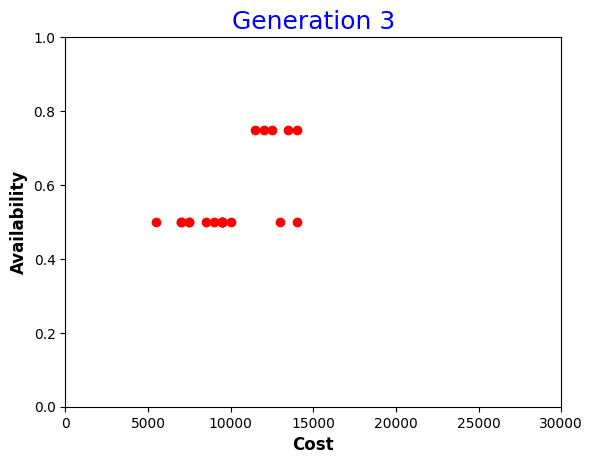



 >>>> CROSSOVER PHASE (with probability 0.2 )



Number of Crossover Children: 0 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [4, 0, 2, 4, 1, 2, 0] not mutated
individual [3, 4, 4, 4, 0, 3, 1] not mutated
individual [4, 1, 2, 4, 1, 2, 0] not mutated
individual [1, 0, 4, 3, 2, 2, 3] not mutated
individual [2, 2, 2, 2, 4, 4, 4] not mutated
individual [2, 1, 3, 3, 4, 0, 2] not mutated
individual [4, 2, 4, 3, 2, 2, 1] not mutated
individual [0, 1, 4, 3, 4, 2, 0] not mutated
individual [4, 3, 4, 3, 2, 3, 2] not mutated
individual [1, 0, 3, 1, 0, 3, 3] not mutated
individual [3, 1, 2, 1, 4, 1, 3] not mutated
individual [0, 3, 4, 1, 1, 2, 0] not mutated
individual [1, 0, 3, 0, 4, 3, 0] not mutated
individual [2, 2, 4, 0, 4, 4, 4] not mutated
individual [0, 3, 2, 3, 3, 4, 0] not mutated
individual [4, 2, 4, 0, 4, 3, 1] not mutated
individual [1, 2, 4, 1, 1, 0, 3] not mutated
individual [1, 3, 4, 1, 2, 4, 3] not mutated

GENERATION: 4 

Individual: [3, 1, 2, 1, 2, 0, 1] Cost:

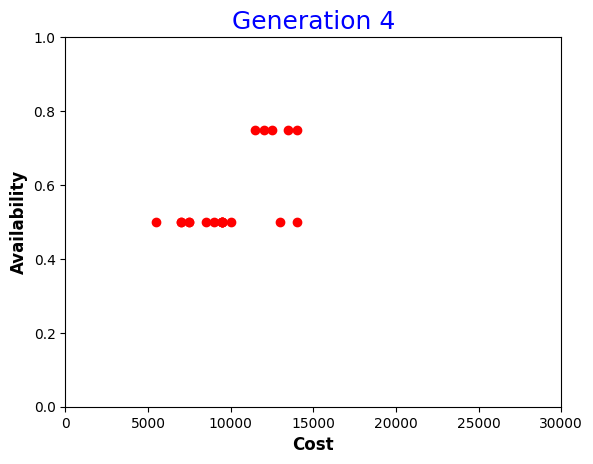



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [1, 0, 3, 1, 0, 3, 3] [0, 3, 2, 3, 3, 4, 0]
Cross from gene: 5

   Child 1 [1, 0, 3, 1, 0, 4, 0]
   Child 2 [0, 3, 2, 3, 3, 3, 3] 

Parents [1, 2, 4, 1, 1, 0, 3] [0, 3, 4, 1, 1, 2, 0]
Cross from gene: 1

   Child 1 [1, 3, 4, 1, 1, 2, 0]
   Child 2 [0, 2, 4, 1, 1, 0, 3] 

Parents [3, 1, 2, 1, 4, 1, 3] [1, 2, 4, 1, 1, 0, 3]
Cross from gene: 5

   Child 1 [3, 1, 2, 1, 4, 0, 3]
   Child 2 [1, 2, 4, 1, 1, 1, 3] 


Number of Crossover Children: 6 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [4, 0, 2, 4, 1, 2, 0] not mutated
individual [3, 4, 4, 4, 0, 3, 1] not mutated
individual [4, 1, 2, 4, 1, 2, 0] mutate to ----->  [4, 1, 2, 4, 0, 4, 0]
individual [1, 0, 4, 3, 2, 2, 3] not mutated
individual [2, 2, 2, 2, 4, 4, 4] not mutated
individual [2, 1, 3, 3, 4, 0, 2] mutate to ----->  [2, 0, 4, 3, 4, 0, 2]
individual [4, 2, 4, 3, 2, 2, 1] not mutated
individual [0, 1, 4, 3, 4, 2, 0] not mutated
individual [4, 3, 4, 3, 2, 3, 

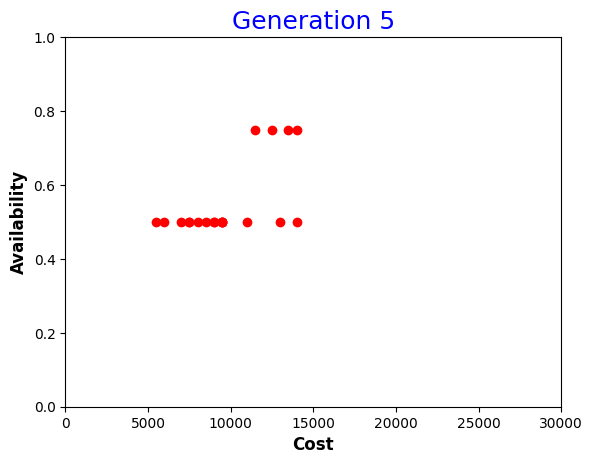



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [0, 3, 2, 3, 3, 3, 3] [4, 1, 2, 4, 0, 4, 0]
Cross from gene: 3

   Child 1 does not comply with the constraints

   Child 2 [4, 1, 2, 3, 3, 3, 3] 

Parents [4, 3, 4, 3, 2, 3, 2] [2, 2, 4, 0, 4, 4, 4]
Cross from gene: 5

   Child 1 does not comply with the constraints

   Child 2 [2, 2, 4, 0, 4, 3, 2] 


Number of Crossover Children: 2 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [1, 0, 3, 1, 0, 4, 0] not mutated
individual [0, 3, 2, 3, 3, 3, 3] not mutated
individual [1, 3, 4, 1, 1, 2, 0] not mutated
individual [0, 2, 4, 1, 1, 0, 3] not mutated
individual [3, 1, 2, 1, 4, 0, 3] not mutated
individual [1, 2, 4, 1, 1, 1, 3] not mutated
individual [4, 0, 2, 4, 1, 2, 0] not mutated
individual [3, 4, 4, 4, 0, 3, 1] mutate to ----->  [1, 4, 4, 4, 0, 4, 1]
individual [1, 0, 4, 3, 2, 2, 3] not mutated
individual [2, 2, 2, 2, 4, 4, 4] not mutated
individual [2, 0, 4, 3, 4, 0, 2] not mutated
individual [4, 2, 4, 3, 2, 2, 1

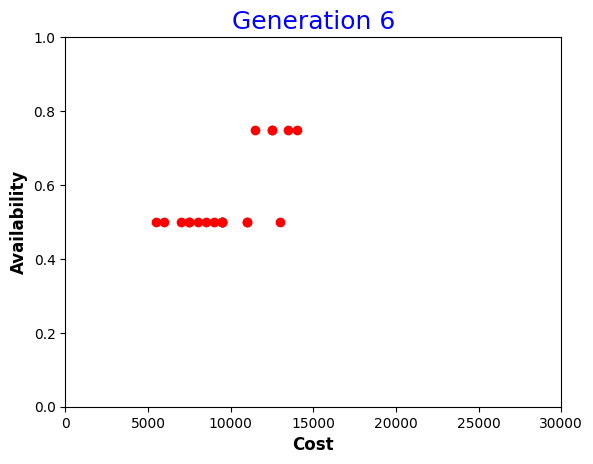



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [1, 3, 4, 1, 1, 2, 0] [0, 2, 4, 1, 1, 0, 3]
Cross from gene: 1

   Child 1 [1, 2, 4, 1, 1, 0, 3]
   Child 2 [0, 3, 4, 1, 1, 2, 0] 

Parents [1, 3, 4, 1, 1, 2, 0] [0, 3, 2, 3, 3, 3, 3]
Cross from gene: 4

   Child 1 [1, 3, 4, 1, 3, 3, 3]
   Child 2 [0, 3, 2, 3, 1, 2, 0] 


Number of Crossover Children: 4 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [4, 1, 2, 3, 3, 3, 3] not mutated
individual [2, 2, 4, 0, 4, 3, 2] not mutated
individual [1, 0, 3, 1, 0, 4, 0] not mutated
individual [3, 1, 2, 1, 4, 0, 3] mutate to ----->  [0, 1, 2, 3, 4, 0, 3]
individual [1, 2, 4, 1, 1, 1, 3] not mutated
individual [4, 0, 2, 4, 1, 2, 0] not mutated
individual [1, 4, 4, 4, 0, 4, 1] not mutated
individual [1, 0, 4, 3, 2, 2, 3] not mutated
individual [2, 2, 2, 2, 4, 4, 4] not mutated
individual [2, 0, 4, 3, 4, 0, 2] not mutated
individual [4, 2, 4, 3, 2, 2, 1] not mutated
individual [0, 1, 4, 3, 4, 2, 0] not mutated
individual [4, 3, 

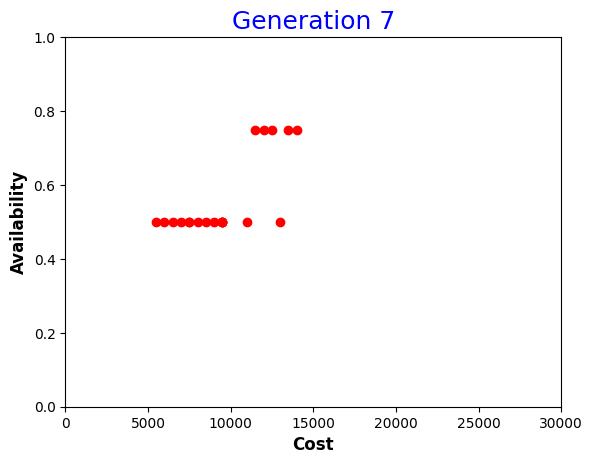



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [2, 2, 2, 2, 4, 4, 4] [2, 0, 4, 3, 4, 0, 2]
Cross from gene: 1

   Child 1 [2, 0, 4, 3, 4, 0, 2]
   Child 2 [2, 2, 2, 2, 4, 4, 4] 

Parents [1, 2, 4, 1, 1, 1, 3] [1, 0, 3, 0, 4, 3, 0]
Cross from gene: 6

   Child 1 [1, 2, 4, 1, 1, 1, 0]
   Child 2 [1, 0, 3, 0, 4, 3, 3] 

Parents [0, 3, 4, 1, 1, 2, 0] [2, 0, 4, 3, 4, 0, 2]
Cross from gene: 4

   Child 1 [0, 3, 4, 1, 4, 0, 2]
   Child 2 [2, 0, 4, 3, 1, 2, 0] 


Number of Crossover Children: 6 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [1, 2, 4, 1, 1, 0, 3] not mutated
individual [1, 3, 4, 1, 3, 3, 3] not mutated
individual [0, 3, 2, 3, 1, 2, 0] mutate to ----->  [0, 3, 4, 3, 1, 2, 0]
individual [4, 1, 2, 3, 3, 3, 3] not mutated
individual [2, 2, 4, 0, 4, 3, 2] not mutated
individual [1, 0, 3, 1, 0, 4, 0] not mutated
individual [0, 1, 2, 3, 4, 0, 3] not mutated
individual [4, 0, 2, 4, 1, 2, 0] not mutated
individual [1, 4, 4, 4, 0, 4, 1] not mutated
individual [1

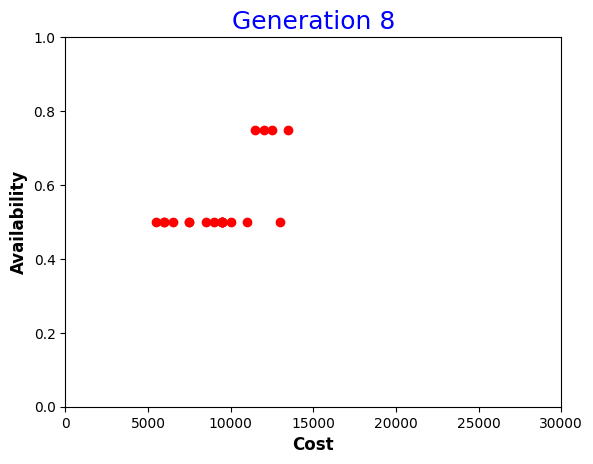



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [1, 2, 4, 1, 1, 0, 3] [1, 2, 4, 1, 1, 1, 0]
Cross from gene: 4

   Child 1 [1, 2, 4, 1, 1, 1, 0]
   Child 2 [1, 2, 4, 1, 1, 0, 3] 

Parents [1, 3, 4, 1, 3, 3, 3] [1, 4, 4, 4, 0, 4, 1]
Cross from gene: 5

   Child 1 [1, 3, 4, 1, 3, 4, 1]
   Child 2 [1, 4, 4, 4, 0, 3, 3] 


Number of Crossover Children: 4 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [2, 0, 4, 3, 4, 0, 2] not mutated
individual [2, 2, 2, 2, 4, 4, 4] not mutated
individual [1, 0, 3, 0, 4, 3, 3] not mutated
individual [0, 3, 4, 1, 4, 0, 2] not mutated
individual [2, 0, 4, 3, 1, 2, 0] not mutated
individual [0, 3, 4, 3, 1, 2, 0] not mutated
individual [4, 1, 2, 3, 3, 3, 3] not mutated
individual [2, 2, 4, 0, 4, 3, 2] not mutated
individual [1, 0, 3, 1, 0, 4, 0] not mutated
individual [0, 1, 2, 3, 4, 0, 3] not mutated
individual [4, 0, 2, 4, 1, 2, 0] not mutated
individual [1, 0, 4, 3, 2, 2, 3] not mutated
individual [4, 2, 4, 3, 2, 2, 1] not mutated
i

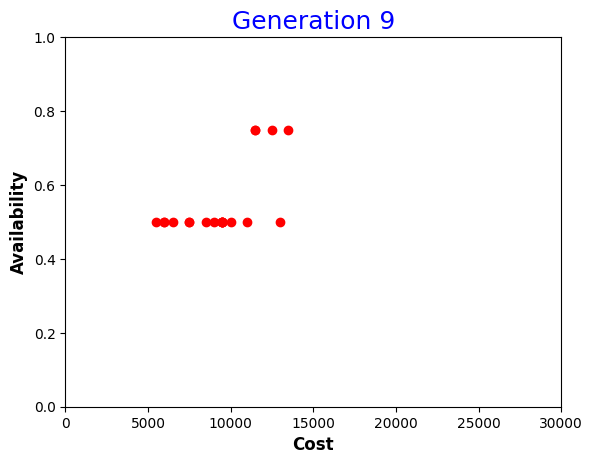



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [4, 1, 2, 3, 3, 3, 3] [2, 2, 4, 0, 4, 3, 2]
Cross from gene: 6

   Child 1 [4, 1, 2, 3, 3, 3, 2]
   Child 2 [2, 2, 4, 0, 4, 3, 3] 

Parents [4, 0, 2, 4, 1, 2, 0] [1, 0, 3, 1, 0, 4, 0]
Cross from gene: 4

   Child 1 [4, 0, 2, 4, 0, 4, 0]
   Child 2 [1, 0, 3, 1, 1, 2, 0] 

Parents [1, 2, 4, 1, 1, 0, 3] [1, 0, 4, 3, 2, 2, 3]
Cross from gene: 6

   Child 1 [1, 2, 4, 1, 1, 0, 3]
   Child 2 [1, 0, 4, 3, 2, 2, 3] 

Parents [2, 2, 4, 0, 4, 3, 2] [1, 0, 4, 3, 2, 2, 3]
Cross from gene: 3

   Child 1 [2, 2, 4, 3, 2, 2, 3]
   Child 2 [1, 0, 4, 0, 4, 3, 2] 


Number of Crossover Children: 8 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [1, 2, 4, 1, 1, 1, 0] mutate to ----->  [0, 2, 4, 1, 3, 1, 0]
individual [1, 4, 4, 4, 0, 3, 3] not mutated
individual [2, 0, 4, 3, 4, 0, 2] not mutated
individual [2, 2, 2, 2, 4, 4, 4] not mutated
individual [1, 0, 3, 0, 4, 3, 3] not mutated
individual [0, 3, 4, 1, 4, 0, 2] not mutated
individu

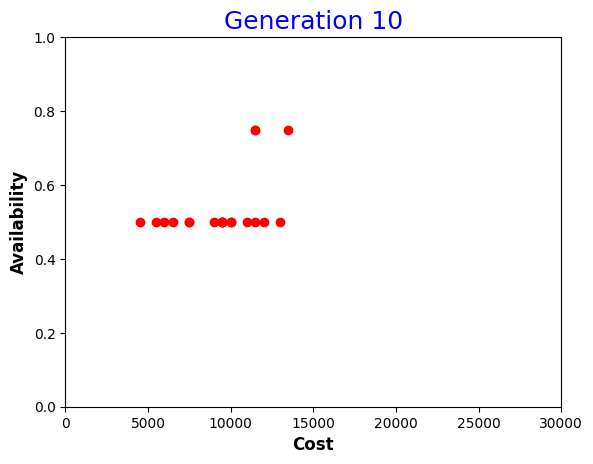



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [0, 2, 4, 1, 3, 1, 0] [4, 0, 2, 4, 0, 4, 0]
Cross from gene: 1

   Child 1 does not comply with the constraints

   Child 2 [4, 2, 4, 1, 3, 1, 0] 


Number of Crossover Children: 1 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [3, 1, 2, 1, 2, 0, 1] not mutated
individual [4, 1, 2, 3, 3, 3, 2] not mutated
individual [2, 2, 4, 0, 4, 3, 3] not mutated
individual [1, 2, 4, 1, 1, 0, 3] not mutated
individual [1, 0, 4, 3, 2, 2, 3] mutate to ----->  [1, 0, 4, 3, 3, 2, 3]
individual [2, 2, 4, 3, 2, 2, 3] not mutated
individual [1, 0, 4, 0, 4, 3, 2] not mutated
individual [0, 2, 4, 1, 3, 1, 0] not mutated
individual [1, 4, 4, 4, 0, 3, 3] not mutated
individual [2, 0, 4, 3, 4, 0, 2] not mutated
individual [2, 2, 2, 2, 4, 4, 4] not mutated
individual [1, 0, 3, 0, 4, 3, 3] not mutated
individual [0, 3, 4, 1, 4, 0, 2] not mutated
individual [2, 0, 4, 3, 1, 2, 0] not mutated
individual [0, 3, 4, 3, 1, 2, 0] mutate to ----->  [

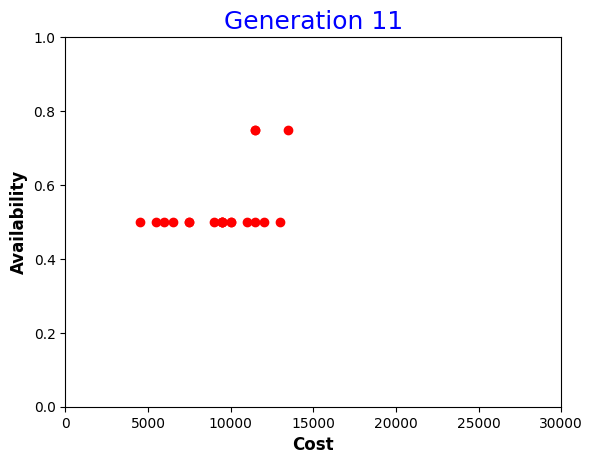



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [0, 4, 2, 1, 4, 0, 3] [2, 2, 2, 2, 4, 4, 4]
Cross from gene: 1

   Child 1 [0, 2, 2, 2, 4, 4, 4]
   Child 2 [2, 4, 2, 1, 4, 0, 3] 

Parents [2, 2, 2, 2, 4, 4, 4] [2, 2, 4, 3, 2, 2, 3]
Cross from gene: 4

   Child 1 [2, 2, 2, 2, 2, 2, 3]

   Child 2 does not comply with the constraints

Parents [2, 0, 4, 3, 4, 0, 2] [3, 1, 2, 1, 2, 0, 1]
Cross from gene: 3

   Child 1 [2, 0, 4, 1, 2, 0, 1]
   Child 2 [3, 1, 2, 3, 4, 0, 2] 


Number of Crossover Children: 5 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [4, 2, 4, 1, 3, 1, 0] not mutated
individual [4, 1, 2, 3, 3, 3, 2] not mutated
individual [2, 2, 4, 0, 4, 3, 3] not mutated
individual [1, 2, 4, 1, 1, 0, 3] not mutated
individual [1, 0, 4, 3, 3, 2, 3] not mutated
individual [2, 2, 4, 3, 2, 2, 3] mutate to ----->  [2, 3, 4, 3, 0, 2, 3]
individual [1, 0, 4, 0, 4, 3, 2] not mutated
individual [0, 2, 4, 1, 3, 1, 0] not mutated
individual [1, 4, 4, 4, 0, 3, 3] not mutate

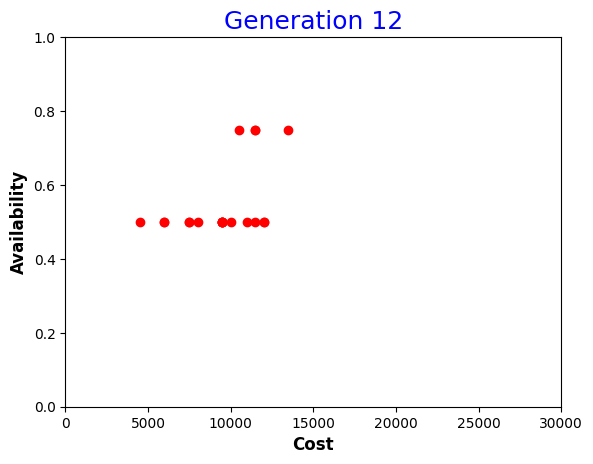



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [1, 3, 4, 1, 3, 4, 1] [0, 2, 2, 2, 4, 4, 4]
Cross from gene: 3

   Child 1 does not comply with the constraints

   Child 2 [0, 2, 2, 1, 3, 4, 1] 


Number of Crossover Children: 1 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [1, 3, 2, 3, 2, 4, 3] not mutated
individual [1, 3, 4, 1, 3, 4, 1] not mutated
individual [2, 2, 2, 2, 2, 2, 3] not mutated
individual [2, 0, 4, 1, 2, 0, 1] not mutated
individual [3, 1, 2, 3, 4, 0, 2] not mutated
individual [4, 2, 4, 1, 3, 1, 0] not mutated
individual [4, 1, 2, 3, 3, 3, 2] not mutated
individual [2, 2, 4, 0, 4, 3, 3] not mutated
individual [1, 2, 4, 1, 1, 0, 3] not mutated
individual [1, 0, 4, 3, 3, 2, 3] not mutated
individual [2, 3, 4, 3, 0, 2, 3] not mutated
individual [1, 0, 4, 0, 4, 3, 2] not mutated
individual [0, 2, 4, 1, 3, 1, 0] mutate to ----->  [0, 2, 4, 3, 2, 1, 0]
individual [1, 4, 4, 4, 0, 3, 3] not mutated
individual [1, 0, 3, 0, 4, 3, 3] not mutated
individ

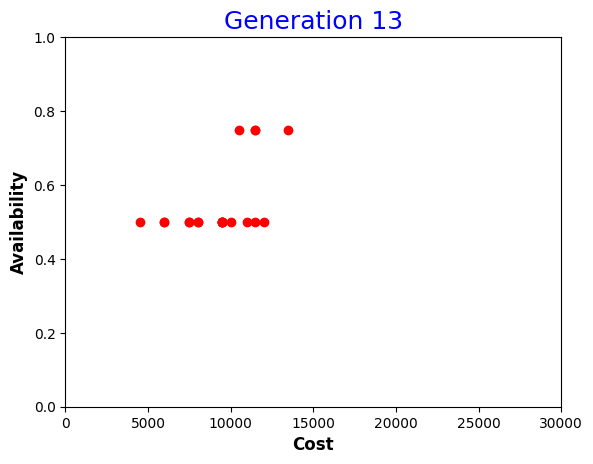



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [0, 2, 4, 3, 2, 1, 0] [4, 1, 2, 3, 3, 3, 2]
Cross from gene: 2

   Child 1 [0, 2, 2, 3, 3, 3, 2]
   Child 2 [4, 1, 4, 3, 2, 1, 0] 

Parents [0, 3, 4, 1, 4, 0, 2] [2, 0, 4, 1, 2, 0, 1]
Cross from gene: 1

   Child 1 does not comply with the constraints

   Child 2 [2, 3, 4, 1, 4, 0, 2] 

Parents [1, 3, 4, 1, 3, 4, 1] [4, 2, 4, 1, 3, 1, 0]
Cross from gene: 3

   Child 1 [1, 3, 4, 1, 3, 1, 0]
   Child 2 [4, 2, 4, 1, 3, 4, 1] 

Parents [1, 4, 4, 4, 0, 3, 3] [2, 3, 4, 3, 0, 2, 3]
Cross from gene: 2

   Child 1 [1, 4, 4, 3, 0, 2, 3]
   Child 2 [2, 3, 4, 4, 0, 3, 3] 


Number of Crossover Children: 7 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [0, 2, 2, 1, 3, 4, 1] not mutated
individual [1, 3, 2, 3, 2, 4, 3] not mutated
individual [2, 2, 2, 2, 2, 2, 3] not mutated
individual [3, 1, 2, 3, 4, 0, 2] not mutated
individual [2, 2, 4, 0, 4, 3, 3] not mutated
individual [1, 2, 4, 1, 1, 0, 3] not mutated
individual [1, 0, 4,

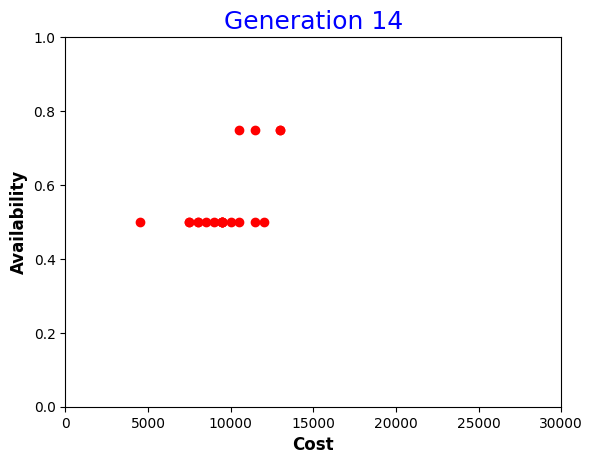



 >>>> CROSSOVER PHASE (with probability 0.2 )


Parents [1, 0, 4, 3, 3, 2, 3] [0, 3, 4, 1, 4, 0, 2]
Cross from gene: 6

   Child 1 [1, 0, 4, 3, 3, 2, 2]
   Child 2 [0, 3, 4, 1, 4, 0, 3] 

Parents [1, 3, 2, 3, 2, 4, 3] [2, 3, 4, 4, 0, 3, 3]
Cross from gene: 1

   Child 1 [1, 3, 4, 4, 0, 3, 3]
   Child 2 [2, 3, 2, 3, 2, 4, 3] 


Number of Crossover Children: 4 



 >>>> MUTATION PHASE (with probability 0.1 )


individual [0, 2, 2, 3, 3, 3, 2] not mutated
individual [4, 1, 4, 3, 2, 1, 0] not mutated
individual [2, 3, 4, 1, 4, 0, 2] mutate to ----->  [2, 3, 4, 0, 4, 1, 2]
individual [1, 3, 4, 1, 3, 1, 0] not mutated
individual [4, 2, 4, 1, 3, 4, 1] not mutated
individual [1, 4, 4, 3, 0, 2, 3] not mutated
individual [0, 2, 2, 1, 3, 4, 1] not mutated
individual [2, 2, 2, 2, 2, 2, 3] not mutated
individual [3, 1, 2, 3, 4, 0, 2] not mutated
individual [2, 2, 4, 0, 4, 3, 3] mutate to ----->  [1, 2, 4, 0, 4, 3, 4]
individual [1, 2, 4, 1, 1, 0, 3] not mutated
individual [1, 0, 4, 0, 4, 0, 3] no

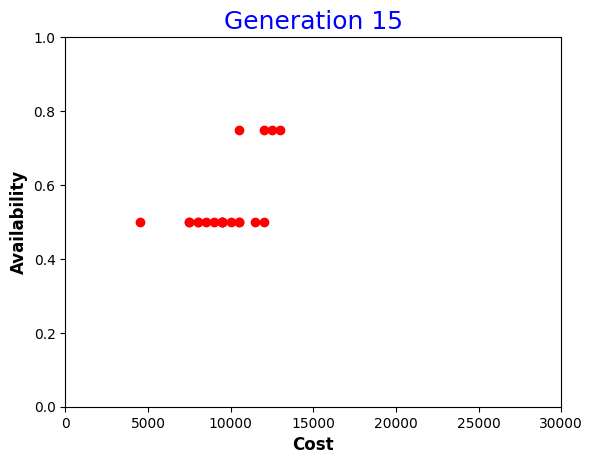

In [50]:
if __name__ == '__main__':
    main()


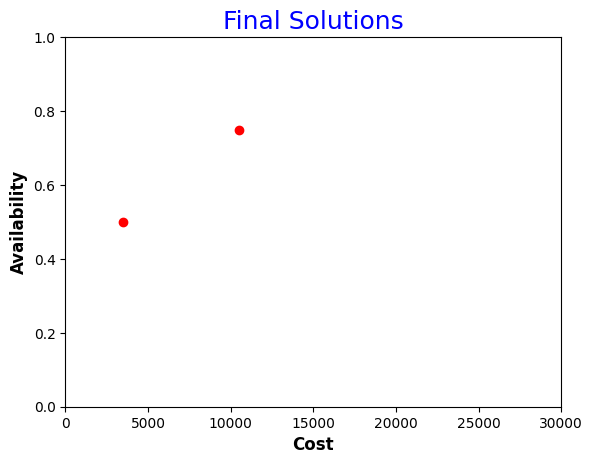

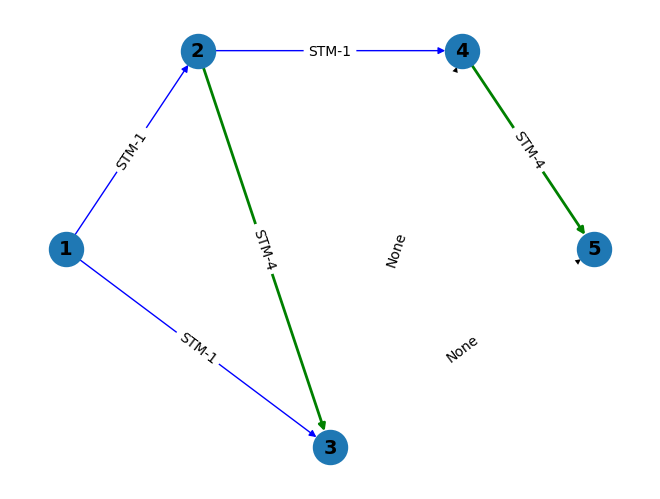

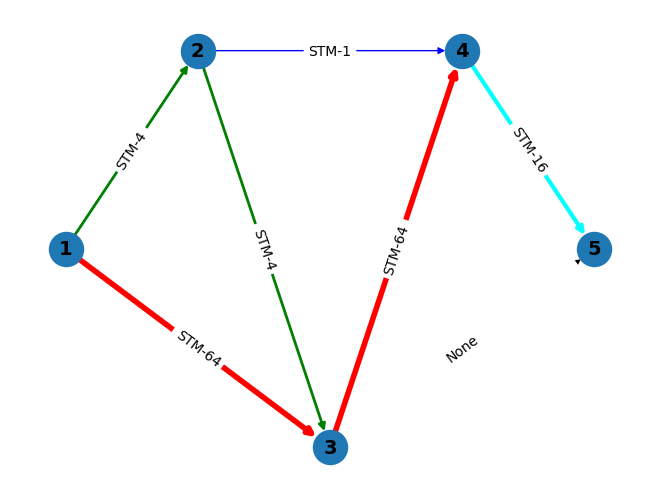

In [26]:
# To plot a list of individuals (final solutions, so non-dominated) create a list,
# using the function CreateSolution(individual, cost, availability)

# EXAMPLE (Put YOUR non-dominated solutions, adding your individuals, cost and availability!):
# Consider that the solution is:
# Individual 1: [1,1,2,1,0,0,2] with cost 3500 and availability 0.5
# Individual 2: [2, 4, 2, 1, 4, 0, 3] with cost 10500 and availability 0.75

DominantIndividuals=[]

sol = CreateSolution([1, 1, 2, 1, 0, 0, 2],3500.0, 0.5)
DominantIndividuals.append(sol)

sol = CreateSolution([2, 4, 2, 1, 4, 0, 3], 10500.0, 0.75)
DominantIndividuals.append(sol)

PlotPopulation(DominantIndividuals,'Final Solutions')
DrawFinalNetworks(DominantIndividuals)

<div class="alert alert-block  alert-success">
<font size="4"><font color=green><b>EXERCISES</b></font></font> 
</div>

-----------------------------------------------------------------------------------------------------------------------

### <font color=blue><b>EXERCISE 1</b></font>.- 


#### Execute the program and analyse the results of $\underline{\text{one generation with mutated individuals}}$ to answer the following questions:

(a) How many individuals are in a generation?

(b) Let consider the first individual of this generation. What represents the information of this individual?

(c) How many individuals are crossed? (crossover)

(d) Explain one example of crossover of your execution.

(e) How many individuals are mutated?

(f) Explain one example of mutation of your execution, and what represents over the network.

(g) Determine what individuals are dominated and what are non-dominated, and explain why.
 

-----------------------------------------------------------------------------------------------------------------------

### <font color=blue><b>EXERCISE 2</b></font>.- 

#### Run all the generations and determine what are the solutions of the Pareto Front. Which traffic demands have been served successfully?

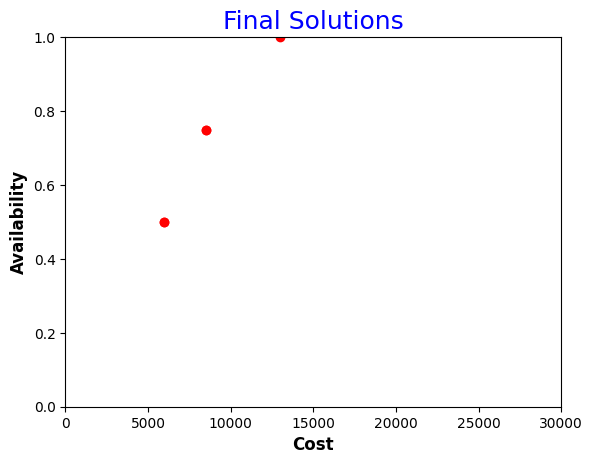

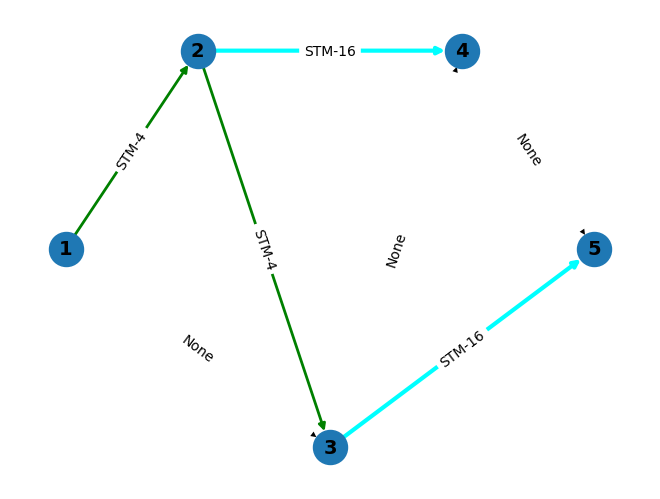

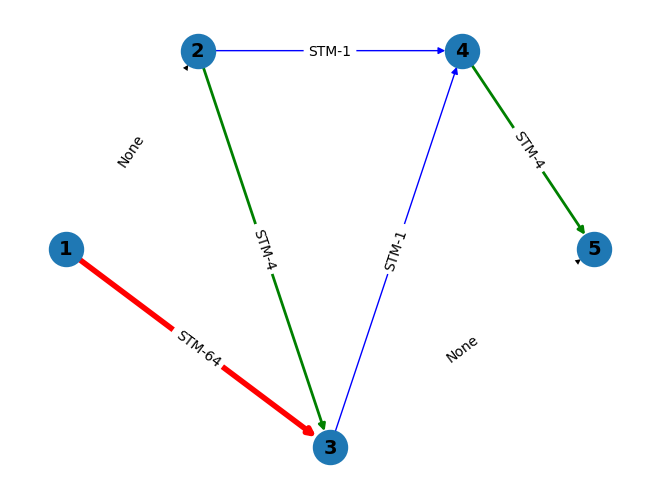

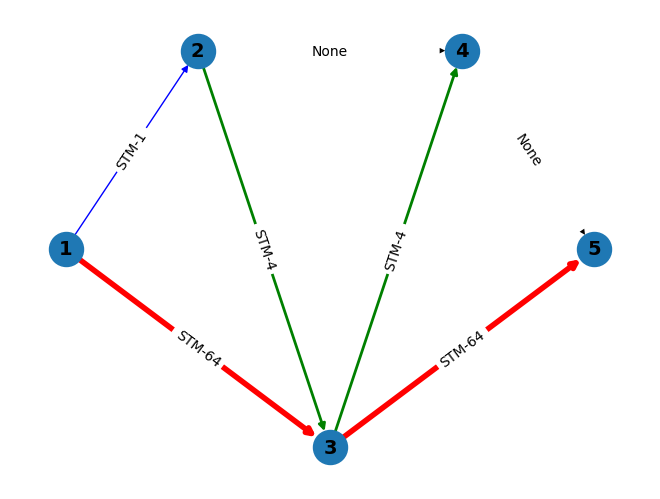

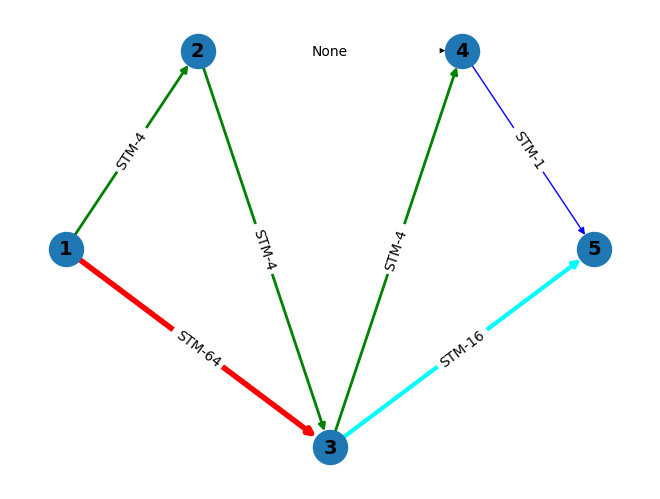

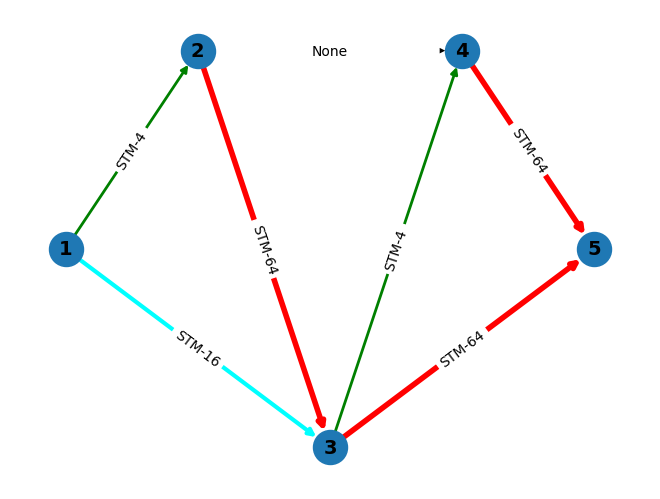

In [28]:
# To plot a list of individuals (final solutions, so non-dominated) create a list,
# using the function CreateSolution(individual, cost, availability)

# EXAMPLE (Put YOUR non-dominated solutions, adding your individuals, cost and availability!):
# Consider that the solution is:
# Individual 1: [1,1,2,1,0,0,2] with cost 3500 and availability 0.5
# Individual 2: [2, 4, 2, 1, 4, 0, 3] with cost 10500 and availability 0.75

DominantIndividuals=[]

sol = CreateSolution([2, 0, 2, 3, 0, 3, 0],6000.0, 0.5)
DominantIndividuals.append(sol)

sol = CreateSolution([0, 4, 2, 1, 1, 0, 2],6000.0, 0.5)
DominantIndividuals.append(sol)

sol = CreateSolution([1, 4, 2, 0, 2, 4, 0],8500.0, 0.75)
DominantIndividuals.append(sol)

sol = CreateSolution([2, 4, 2, 0, 2, 3, 1],8500.0, 0.75)
DominantIndividuals.append(sol)

sol = CreateSolution([2, 3, 4, 0, 2, 4, 4], 13000.0, 1.0)
DominantIndividuals.append(sol)

PlotPopulation(DominantIndividuals,'Final Solutions')
DrawFinalNetworks(DominantIndividuals)

-----------------------------------------------------------------------------------------------------------------------

### <font color=blue><b>EXERCISE 3</b></font>.- 

#### Change the value of the crossover probability (pc) and explain which is the influence of this parameter to obtain the solution of the problem, considering pc=0.2 and pc=0.8.

-----------------------------------------------------------------------------------------------------------------------

### <font color=blue><b>EXERCISE 4</b></font>.- 

#### Analyse what is the influence of the constraints of the problem, i.e., the maximum cost (CostLimit) and the minimum availability (AvLimit) defined as a parameters. What happens if the CostLimit is decreased or the AvLimit is increased?